# Session 3 · My first CNN

The ANN needed a separate weight for every pixel position. I replaced its first dense layer with small filters that use the same weights across the image. I also kept one scratch from the gallery for a separate check of what happens when the defect moves.

In [1]:
from pathlib import Path
from copy import deepcopy
import hashlib
import json
import torch.nn.functional as F

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

seed = 42
torch.manual_seed(seed)
torch.set_num_threads(min(4, torch.get_num_threads()))
artifacts = Path("Artifacts")
manifest_path = artifacts / "split_manifest.csv"
manifest = pd.read_csv(manifest_path)
classes = sorted(manifest.loc[manifest.split == "train", "label"].unique().tolist())
class_ids = list(range(len(classes)))
label_id = {name: i for i, name in enumerate(classes)}
assert len(classes) == 6
train_rows = manifest.loc[manifest.split == "train"].reset_index(drop=True)
val_rows = manifest.loc[manifest.split == "validation"].reset_index(drop=True)
assert train_rows.label.value_counts().reindex(classes).eq(210).all()
assert val_rows.label.value_counts().reindex(classes).eq(45).all()
assert set(train_rows.pixel_sha256).isdisjoint(val_rows.pixel_sha256)
print(f"{len(train_rows)} training images, {len(val_rows)} validation images. Running on CPU.")

manifest_digest = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
ann_saved = torch.load(artifacts / "ann_baseline.pt", map_location="cpu", weights_only=True)
ann_metrics = json.loads((artifacts / "ann_validation.json").read_text(encoding="utf-8"))
for previous in (ann_saved, ann_metrics):
    assert previous["classes"] == classes and previous["manifest_sha256"] == manifest_digest
assert ann_saved["validation_macro_f1"] == ann_metrics["validation_macro_f1"]

1260 training images, 270 validation images. Running on CPU.


## What I kept fixed

I reused the ANN’s training-set normalization and the same full-resolution images. Both runs used Adam at 0.0003, batches of 64 and 20 epochs. This first CNN had two convolutional blocks.

In [2]:
def load_images(rows):
    pixels = torch.empty((len(rows), 1, 200, 200), dtype=torch.uint8)
    for index, row in enumerate(rows.itertuples(index=False)):
        with Image.open(row.path) as image:
            if image.size != (200, 200) or image.mode != "L":
                raise ValueError(f"Unexpected image format: {row.path}")
            if hashlib.sha256(image.tobytes()).hexdigest() != row.pixel_sha256:
                raise ValueError(f"Pixel content changed since Session 1: {row.path}")
            pixels[index, 0] = torch.from_numpy(np.array(image))
    targets = torch.tensor(rows.label.map(label_id).tolist(), dtype=torch.long)
    return TensorDataset(pixels, targets)

train_data = load_images(train_rows)
val_data = load_images(val_rows)
mean, std = ann_saved["mean"], ann_saved["std"]

def normalize(pixels):
    return (pixels.float() / 255.0 - mean) / std

batch_size = 64
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,
                          generator=torch.Generator().manual_seed(seed))
val_loader = DataLoader(val_data, batch_size=batch_size)
print(f"Training mean {mean:.4f}, standard deviation {std:.4f} on a 0–1 scale.")

Training mean 0.5009, standard deviation 0.2125 on a 0–1 scale.


## From a 200-pixel crop to a feature map

My first layer uses eight 5 × 5 filters. With stride 2, the filter moves two pixels at a time. Padding adds two pixels on each edge, giving a map width of ⌊(200 + 4 − 5) / 2⌋ + 1 = 100. A 2 × 2 max pool then reduces it to 50 by keeping the strongest response in each window.

After the second block, each position sees a 19 × 19 region of the input. I averaged each channel onto a 4 × 4 grid so the classifier could still use rough location.

In [3]:
def make_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 8, kernel_size=5, stride=2, padding=2),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(8, 16, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.AdaptiveAvgPool2d((4, 4)),
        nn.Flatten(),
        nn.Linear(16 * 4 * 4, len(classes)),
    )

model = make_cnn().to(memory_format=torch.channels_last)
parameter_count = sum(p.numel() for p in model.parameters())
with torch.no_grad():
    activation = normalize(train_data.tensors[0][:1])
    print("Input:", tuple(activation.shape))
    for layer in model:
        activation = layer(activation)
        print(f"{layer.__class__.__name__:18} {tuple(activation.shape)}")
print(f"Trainable parameters: {parameter_count:,}")
assert activation.shape == (1, len(classes))

Input: (1, 1, 200, 200)


Conv2d             (1, 8, 100, 100)
ReLU               (1, 8, 100, 100)
MaxPool2d          (1, 8, 50, 50)
Conv2d             (1, 16, 50, 50)
ReLU               (1, 16, 50, 50)
MaxPool2d          (1, 16, 25, 25)
AdaptiveAvgPool2d  (1, 16, 4, 4)
Flatten            (1, 256)
Linear             (1, 6)
Trainable parameters: 2,918


## Training the two-block model

I used the same checkpoint rule as the ANN. This time the best validation macro F1 came at epoch 20. I kept both curves below because loss and class-level F1 capture different parts of training.

In [4]:
loss_fn = nn.CrossEntropyLoss()
learning_rate = 0.0003
epochs = 20
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
checkpoint = artifacts / "basic_cnn.pt"

@torch.inference_mode()
def validate(network):
    network.eval()
    outputs = torch.cat([network(normalize(x)) for x, _ in val_loader])
    targets = val_data.tensors[1]
    predictions = outputs.argmax(dim=1)
    score = f1_score(targets.numpy(), predictions.numpy(), labels=class_ids,
                     average="macro", zero_division=0)
    return loss_fn(outputs, targets).item(), float(score), predictions

history = []
best_score = -1.0
for epoch in range(1, epochs + 1):
    model.train()
    loss_sum = 0.0
    for pixels, targets in train_loader:
        optimizer.zero_grad(set_to_none=True)
        loss = loss_fn(model(normalize(pixels)), targets)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(targets)
    val_loss, score, predictions = validate(model)
    history.append({"epoch": epoch, "train_loss": loss_sum / len(train_data),
                    "validation_loss": val_loss, "validation_macro_f1": score})
    if score > best_score:
        best_epoch, best_score = epoch, score
        best_predictions = predictions.clone()
        payload = {"state_dict": deepcopy(model.state_dict()), "classes": classes, "input_shape": [1, 200, 200],
                   "architecture": "basic_cnn", "channels": [8, 16], "mean": mean, "std": std, "seed": seed,
                   "epoch": epoch, "validation_macro_f1": score, "manifest_sha256": manifest_digest}
    if epoch == 1 or epoch % 5 == 0:
        print(f"Epoch {epoch:2d} | train loss {history[-1]['train_loss']:.3f} | "
              f"validation loss {val_loss:.3f} | validation macro F1 {score:.3f}")
temporary = checkpoint.with_suffix(".tmp")
torch.save(payload, temporary)
temporary.replace(checkpoint)
print(f"Selected epoch {best_epoch} with validation macro F1 {best_score:.4f}.")

Epoch  1 | train loss 1.776 | validation loss 1.740 | validation macro F1 0.128


Epoch  5 | train loss 1.477 | validation loss 1.417 | validation macro F1 0.446


Epoch 10 | train loss 1.242 | validation loss 1.191 | validation macro F1 0.540


Epoch 15 | train loss 1.057 | validation loss 1.033 | validation macro F1 0.644


Epoch 20 | train loss 0.909 | validation loss 0.894 | validation macro F1 0.712
Selected epoch 20 with validation macro F1 0.7118.


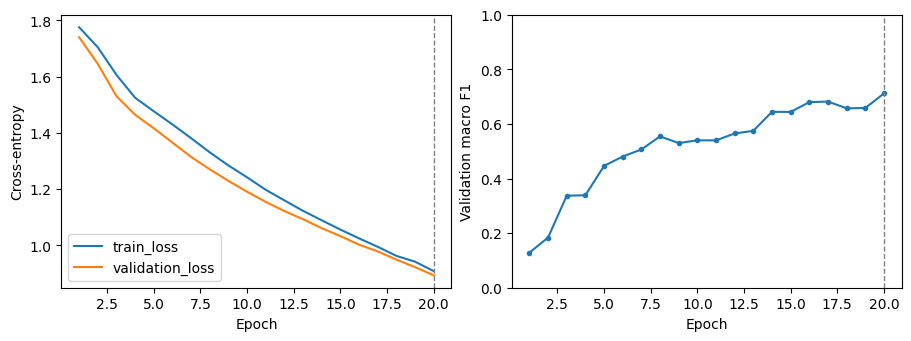

In [5]:
curves = pd.DataFrame(history).set_index("epoch")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), layout="constrained")
curves[["train_loss", "validation_loss"]].plot(ax=axes[0], ylabel="Cross-entropy")
curves.validation_macro_f1.plot(ax=axes[1], marker=".", ylim=(0, 1), ylabel="Validation macro F1")
for ax in axes:
    ax.axvline(best_epoch, color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel("Epoch")
plt.show()

## Checking the ANN’s two biggest mistakes

The CNN got 193 of 270 images right with 2,918 parameters. Crazing called pitted surface fell from 14 cases to zero. Rolled-in scale called patches fell from 14 to one. Scratches were a different story. The CNN recognized 19 of 45, one fewer than the ANN.

In [6]:
saved = torch.load(checkpoint, map_location="cpu", weights_only=True)
restored = make_cnn().to(memory_format=torch.channels_last)
restored.load_state_dict(saved["state_dict"])
_, score, predictions = validate(restored)
assert torch.equal(predictions, best_predictions) and score == saved["validation_macro_f1"]

actual = val_data.tensors[1].numpy()
predicted = predictions.numpy()
report = classification_report(actual, predicted, labels=class_ids, target_names=classes,
                               output_dict=True, zero_division=0)
matrix = confusion_matrix(actual, predicted, labels=class_ids)
previous_matrix = np.array(ann_metrics["validation_confusion_matrix"])
display(pd.DataFrame({
    "model": ["ANN", "Basic CNN"],
    "parameters": [ann_metrics["parameters"], parameter_count],
    "best epoch": [ann_metrics["best_epoch"], best_epoch],
    "validation macro F1": [ann_metrics["validation_macro_f1"], score],
    "correct / 270": [previous_matrix.trace(), matrix.trace()],
}).set_index("model").round(4))
display(pd.DataFrame(matrix, index=pd.Index(classes, name="True label"),
                     columns=pd.Index(classes, name="Predicted label")))
for truth, guess in [("crazing", "pitted_surface"), ("rolled_in_scale", "patches")]:
    pair = label_id[truth], label_id[guess]
    print(f"{truth} predicted as {guess}: ANN {previous_matrix[pair]}/45, CNN {matrix[pair]}/45")

metrics = {"model": "Basic CNN", "parameters": parameter_count, "seed": seed,
           "learning_rate": learning_rate, "batch_size": batch_size, "best_epoch": best_epoch,
           "validation_macro_f1": score, "classes": classes, "validation_report": report,
           "validation_confusion_matrix": matrix.tolist(), "history": history,
           "manifest_sha256": manifest_digest}
(artifacts / "basic_cnn_validation.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

,parameters,best epoch,validation macro F1,correct / 270
model,,,,
ANN,2560454,19,0.5011,138
Basic CNN,2918,20,0.7118,193


Predicted label,crazing,inclusion,patches,pitted_surface,rolled_in_scale,scratches
True label,,,,,,
crazing,37,0,1,0,7,0
inclusion,0,33,0,5,4,3
patches,6,0,36,2,1,0
pitted_surface,1,3,1,38,1,1
rolled_in_scale,8,0,1,0,30,6
scratches,0,13,0,1,12,19


crazing predicted as pitted_surface: ANN 14/45, CNN 0/45
rolled_in_scale predicted as patches: ANN 14/45, CNN 1/45


5473

## Moving the same scratch eight pixels

I shifted `Sc_140` eight pixels to the right and filled the exposed strip with the nearest edge value. I chose the first-layer channel with the most spatial variation on the original crop and used the same scale for both maps. With stride 2, I expected a shift of four columns in the map.

Interior maps align after 4 columns. Maximum absolute difference: 0


,model,image,prediction,P(scratches)
0,ANN,Original,scratches,0.9181
1,ANN,Shifted,patches,0.2771
2,Basic CNN,Original,inclusion,0.2628
3,Basic CNN,Shifted,scratches,0.3048


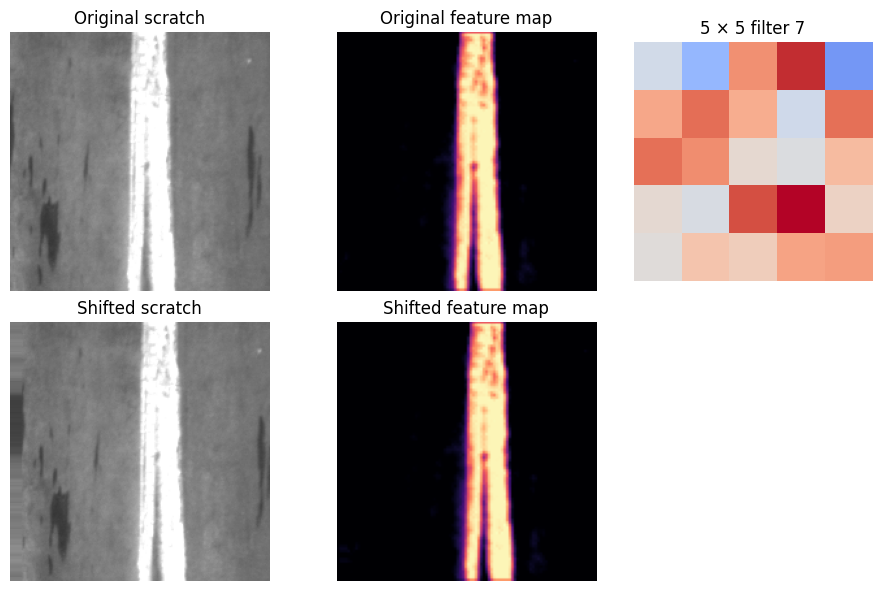

In [7]:
sample_index = train_rows.index[train_rows.path.map(lambda p: Path(p).stem == "Sc_140")].item()
original = normalize(train_data.tensors[0][sample_index:sample_index + 1])
shift = 8
shifted = F.pad(original, (shift, 0, 0, 0), mode="replicate")[..., :original.shape[-1]]
pair = torch.cat((original, shifted))
ann = nn.Sequential(nn.Flatten(), nn.Linear(40000, ann_saved["hidden_units"]), nn.ReLU(),
                    nn.Linear(ann_saved["hidden_units"], len(classes)))
ann.load_state_dict(ann_saved["state_dict"])
ann.eval()
with torch.inference_mode():
    maps = restored[:2](pair)
    channel = maps[0].std(dim=(1, 2)).argmax().item()
    stride = restored[0].stride[1]
    offset = shift // stride
    aligned_error = (maps[0, :, :, 1:-offset-1] - maps[1, :, :, offset+1:-1]).abs().max().item()
    assert aligned_error < 1e-4
    rows = []
    for name, network in [("ANN", ann), ("Basic CNN", restored)]:
        probs = network(pair).softmax(dim=1)
        for i, condition in enumerate(["Original", "Shifted"]):
            rows.append({"model": name, "image": condition,
                         "prediction": classes[probs[i].argmax().item()],
                         "P(scratches)": probs[i, label_id["scratches"]].item()})
print(f"Interior maps align after {offset} columns. Maximum absolute difference: {aligned_error:.2g}")
display(pd.DataFrame(rows).round(4))

fig, axes = plt.subplots(2, 3, figsize=(9, 5.8), layout="constrained",
                         gridspec_kw={"width_ratios": [1, 1, 0.75]})
limit = maps[:, channel].max().item()
for i, condition in enumerate(["Original", "Shifted"]):
    axes[i, 0].imshow(pair[i, 0] * std + mean, cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title(f"{condition} scratch")
    axes[i, 1].imshow(maps[i, channel], cmap="magma", vmin=0, vmax=limit)
    axes[i, 1].set_title(f"{condition} feature map")
kernel = restored[0].weight[channel, 0].detach()
bound = kernel.abs().max().item()
axes[0, 2].imshow(kernel, cmap="coolwarm", vmin=-bound, vmax=bound)
axes[0, 2].set_title(f"5 × 5 filter {channel}")
for ax in axes.flat:
    ax.axis("off")
plt.show()

## What moved with the scratch

Away from the boundaries, the first-layer maps aligned exactly after I shifted them back four columns. The final answer still changed. The CNN called the original crop inclusion and the shifted crop scratches. The ANN changed from scratches to patches. This one image showed me how a filter can follow a mark even when the final label changes.

Of the 45 validation scratches, the CNN called 13 inclusion and 12 rolled-in scale. That led me to try a deeper block that could see more of each mark.